# Lab 2: From text to index — preprocessing and Boolean retrieval
**Course:** Information Retrieval (IR 2026), CADT  |  **Session 2**  |  **Time:** 3 hours  |  *Student version*

In Lab 1 you searched by scanning every document, and you saw it fail on "car", get confused by "cat" inside "category", and get slow as the collection grew. Today you fix the first two problems and set up the third: you will **preprocess text properly**, **build an inverted index**, and **answer Boolean queries by merging postings lists** instead of scanning.

**By the end of this lab you can:**
1. Tokenize and normalize text, and explain what each preprocessing step changes.
2. Remove stop words and apply a simple stemmer, and describe what each one fixes and what it breaks.
3. Build an inverted index (a dictionary of terms to sorted postings lists).
4. Implement the AND, OR and NOT Boolean operators with the merge algorithm on sorted postings.
5. Re-evaluate Lab 1's information needs with your new index and explain what changed.
6. Show, with measurements, why an index answers queries faster than scanning, once it is built.

**How to work:** run the cells in order, replace every `# TODO`, and write your answers in the *Answer* cells. Part 8 (Khmer) is optional; Part 9 can be finished after class.

## Part 0. Setup and recap (about 10 min)
Run the next cell, then look back at your Lab 1 notebook (or the printed answers) for the query **"car"**: it returned zero results even though two documents are about cars. Keep that failure in mind; you will revisit it in Part 6.

In [87]:
import re, sqlite3, time, random
import pandas as pd
import matplotlib.pyplot as plt
from nltk.stem import PorterStemmer

print("Setup OK")

Setup OK


In [88]:
docs = {
    "d01": 'Budget guesthouses in Phnom Penh offer clean rooms near the Riverside for under twenty dollars a night.',
    "d02": 'Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season.',
    "d03": 'The Cambodia Academy of Digital Technology offers degrees in software engineering, data science and cybersecurity.',
    "d04": 'Python is a popular programming language for data science, web development and automation.',
    "d05": 'A ball python is a small, docile snake that is often kept as a pet.',
    "d06": 'Java is a statically typed language widely used for enterprise applications and Android development.',
    "d07": 'Java is an island in Indonesia with more than one hundred million inhabitants.',
    "d08": 'Angkor Wat is the largest religious monument in the world and attracts millions of visitors every year.',
    "d09": 'The Mekong River flows through six countries and supports fishing and rice farming along its banks.',
    "d10": 'Rice is the main crop in Cambodia, and farmers plant it at the start of the rainy season.',
    "d11": 'Fried noodles and fish amok are popular dishes in Cambodian restaurants.',
    "d12": 'Buses run every hour from Phnom Penh to Siem Reap, and the trip takes about six hours.',
    "d13": 'Tuk-tuk drivers in the capital usually negotiate the fare before the ride starts.',
    "d14": 'Electric vehicles are becoming more common as battery prices fall.',
    "d15": 'An automobile engine converts fuel into motion using internal combustion.',
    "d16": 'Her cat sleeps all day, but at night it starts running around the house.',
    "d17": 'The library catalog lists every category of book, from fiction to computer science.',
    "d18": 'To concatenate two strings in Python, use the plus operator.',
    "d19": 'The marathon runners ran through the city streets despite the heat.',
    "d20": 'Apartments with 2 bedrooms near the university are popular with students.',
    "d21": 'Machine learning models learn patterns from data instead of following hand-written rules.',
    "d22": 'Search engines use crawlers to collect web pages and build an index for fast lookup.',
    "d23": 'A database stores structured records in tables and answers precise queries written in SQL.',
    "d24": 'The government announced new investment in digital skills and internet access for rural areas.',
    "d25": 'Coffee shops in the capital are popular places for students to study and meet friends.',
    "d26": 'Khmer script has no spaces between words, which makes text processing harder.',
    "d27": 'Airlines added more flights to the coastal city of Sihanoukville for the holiday season.',
    "d28": 'Learning to program requires regular practice, not only reading books.',
    "d29": 'The National Museum in Phnom Penh displays Khmer sculpture from the Angkorian period.',
    "d30": 'Affordable accommodation for backpackers is available in Kampot, including hostels and homestays.',
}
pd.DataFrame({'id': list(docs), 'text': list(docs.values())}).style.hide(axis='index')

id,text
d01,Budget guesthouses in Phnom Penh offer clean rooms near the Riverside for under twenty dollars a night.
d02,"Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season."
d03,"The Cambodia Academy of Digital Technology offers degrees in software engineering, data science and cybersecurity."
d04,"Python is a popular programming language for data science, web development and automation."
d05,"A ball python is a small, docile snake that is often kept as a pet."
d06,Java is a statically typed language widely used for enterprise applications and Android development.
d07,Java is an island in Indonesia with more than one hundred million inhabitants.
d08,Angkor Wat is the largest religious monument in the world and attracts millions of visitors every year.
d09,The Mekong River flows through six countries and supports fishing and rice farming along its banks.
d10,"Rice is the main crop in Cambodia, and farmers plant it at the start of the rainy season."


## Part 1. Tokenization and normalization (about 25 min)
The first step of preprocessing turns raw text into a list of clean, comparable *tokens*: lower-case words with punctuation and digits removed.

In [89]:
def tokenize(text):
    """Return the list of lower-case word tokens in `text` (letters only)."""
    # TODO: lower-case the text, then use re.findall with a pattern that keeps runs of letters
    lowercase = text.lower()
    return re.findall(r"[a-z]+", lowercase)

In [90]:
for doc_id in ["d02", "d17", "d18"]:
    print(doc_id, "->", tokenize(docs[doc_id]))

d02 -> ['cheap', 'hotel', 'deals', 'in', 'siem', 'reap', 'are', 'easy', 'to', 'find', 'especially', 'during', 'the', 'rainy', 'season']
d17 -> ['the', 'library', 'catalog', 'lists', 'every', 'category', 'of', 'book', 'from', 'fiction', 'to', 'computer', 'science']
d18 -> ['to', 'concatenate', 'two', 'strings', 'in', 'python', 'use', 'the', 'plus', 'operator']


**Answer 1.1** Look at the tokens for `d17` and `d18`. What happened to punctuation, capital letters and numbers? Give one example of information that tokenization throws away that might matter for search.

*Your answer:*
 - ',' was removed ,all string in lowercase ;
 - it matter for search because all string in lowercase which quick for find 

## Part 2. Stop words (about 15 min)
Words like *the*, *is* and *of* appear in almost every document and carry little meaning for search. Removing them shrinks the index and speeds up queries.

In [91]:
STOP_WORDS = set("""a an the is are was were be been being of to in on at for with and or not
this that these those it its as by from into over under about than then so if but""".split())

def remove_stopwords(tokens):
    """Return `tokens` with anything in STOP_WORDS removed."""
    # TODO
    stop_word_removal = [token for token in tokens if token not in STOP_WORDS]
    return stop_word_removal

In [92]:
before = sum(len(tokenize(t)) for t in docs.values())
after = sum(len(remove_stopwords(tokenize(t))) for t in docs.values())
print(f"Tokens before: {before}, after removing stop words: {after} ({100*(before-after)/before:.0f}% smaller)")
print(docs["d17"])
print(remove_stopwords(tokenize(docs["d17"])))

Tokens before: 405, after removing stop words: 284 (30% smaller)
The library catalog lists every category of book, from fiction to computer science.
['library', 'catalog', 'lists', 'every', 'category', 'book', 'fiction', 'computer', 'science']


**Answer 2.1** By what percentage did the total number of tokens shrink? Can you think of a query where removing a "stop word" would lose something important? (Hint: think about a query that is entirely common words, or where word order matters.)

*Your answer:*
- 30% smaller, in this case tokeniation wont affect the query since every key term is keep

## Part 3. Stemming (about 25 min)
Stemming strips endings so that related forms (*run*, *running*) map to the same term. Real systems use algorithms such as the Porter stemmer. We will write a much simpler, rule-based version and see where it breaks.

In [93]:
SUFFIXES = ["ational", "tional", "alize", "ation", "ative", "fulness", "ousness",
            "iveness", "ing", "ies", "ied", "ly", "ed", "es", "s"]

def simple_stem(word):
    """Strip the first matching suffix in SUFFIXES, keeping at least 3 characters."""
    # TODO: try each suffix in order; if word ends with it AND the remainder has
    #       at least 3 characters, return the remainder; otherwise return word unchanged
    if len(word)<=3:
        return word
    for suffix in SUFFIXES:
        if word.endswith(suffix):
            return word[: -len(suffix)]
    return word

def stem_all(tokens):
    return [simple_stem(t) for t in tokens]

In [94]:
for w in ["running", "ran", "runners", "farms", "farming", "farmers", "categories", "category", "cats"]:
    print(f"{w:>12} -> {simple_stem(w)}")

stemmer = PorterStemmer()

for w in [
    "running",
    "ran",
    "runners",
    "farms",
    "farming",
    "farmers",
    "categories",
    "category",
    "cats",
]:
    print(f"{w} -> {stemmer.stem(w)}")

     running -> runn
         ran -> ran
     runners -> runner
       farms -> farm
     farming -> farm
     farmers -> farmer
  categories -> categor
    category -> category
        cats -> cat
running -> run
ran -> ran
runners -> runner
farms -> farm
farming -> farm
farmers -> farmer
categories -> categori
category -> categori
cats -> cat


**Answer 3.1** Which words above end up with the SAME stem even though they should? Which words should share a stem but do NOT? What does this tell you about a simple, rule-based stemmer versus a real one (e.g. the Porter stemmer)?

*Your answer:*
- categroy and categories. should end up with same stem
- running and ran should share stem
- simple rule base might not clean all word like have Porter stemmers n in runn. category to None. 

## Part 4. Build the inverted index (about 25 min)
Combine tokenize, remove_stopwords and simple_stem into one pipeline, then build a **dictionary of term → sorted list of document ids** (the postings list): the core data structure behind every search engine.

In [95]:
def preprocess(text):
    """Run the full pipeline: tokenize, remove stop words, then stem."""
    # TODO: chain the three functions you wrote above
    text = tokenize(text)
    text = remove_stopwords(text)
    text = [simple_stem(t) for t in text]
    # text = [stemmer.stem(t) for t in text]
    text = [(t) for t in text]

    return text

print(preprocess(docs["d17"]))

['library', 'catalog', 'list', 'every', 'category', 'book', 'fiction', 'computer', 'science']


In [96]:
def build_index(docs):
    """Return {term: sorted list of doc ids that contain the term}."""
    # TODO: for each (doc_id, text) in docs.items(), preprocess the text,
    #       and for each UNIQUE term add doc_id to index[term]; sort every postings list at the end
    index = {}

    for doc_id, text in docs.items():
        processed_text = preprocess(text)

        for term in set(processed_text):
            if term not in index:
                index[term] = []

            index[term].append(doc_id)

    for term in index:
        index[term].sort()

    return index

In [97]:
index = build_index(docs)
print(f"Vocabulary size: {len(index)} terms (from {sum(len(tokenize(t)) for t in docs.values())} raw tokens)")
print(index)
for term in ["cheap", "hotel", "python", "cat", "run", "car", "automobile"]:
    stemmed = simple_stem(term)
    print(f"{term!r} (stem {stemmed!r}) -> {index.get(stemmed, [])}")

Vocabulary size: 234 terms (from 405 raw tokens)
{'dollar': ['d01'], 'budget': ['d01'], 'twenty': ['d01'], 'near': ['d01', 'd20'], 'penh': ['d01', 'd12', 'd29'], 'riverside': ['d01'], 'phnom': ['d01', 'd12', 'd29'], 'room': ['d01'], 'guesthous': ['d01'], 'clean': ['d01'], 'night': ['d01', 'd16'], 'offer': ['d01', 'd03'], 'easy': ['d02'], 'siem': ['d02', 'd12'], 'dur': ['d02'], 'find': ['d02'], 'rainy': ['d02', 'd10'], 'deal': ['d02'], 'especial': ['d02'], 'reap': ['d02', 'd12'], 'cheap': ['d02'], 'season': ['d02', 'd10', 'd27'], 'hotel': ['d02'], 'technology': ['d03'], 'software': ['d03'], 'data': ['d03', 'd04', 'd21'], 'cambodia': ['d03', 'd10'], 'degre': ['d03'], 'cybersecurity': ['d03'], 'engineer': ['d03'], 'academy': ['d03'], 'digital': ['d03', 'd24'], 'science': ['d03', 'd04', 'd17'], 'popular': ['d04', 'd11', 'd20', 'd25'], 'programm': ['d04'], 'development': ['d04', 'd06'], 'autom': ['d04'], 'language': ['d04', 'd06'], 'web': ['d04', 'd22'], 'python': ['d04', 'd05', 'd18'], 'do

**Answer 4.1** Which of the terms above has the longest postings list, and which have an empty one? A term with a very short postings list is sometimes called "informative" — why?

*Your answer:*
- phyton have the long posting list (`d04,d05`)'
- car hvae an empty
- short postings require fewer judgments and comparisons, making it easier to read and find the relevant results. 

## Part 5. Boolean retrieval with the merge algorithm (about 35 min)
Because postings lists are **sorted**, we can intersect (AND) or union (OR) two of them in a single left-to-right pass, without scanning any document text. This is the merge algorithm from the lecture.

In [98]:
def intersect(p1, p2):
    """Merge two SORTED postings lists and return their intersection (AND)."""
    # TODO: compare 2 posting list and return back the intersections
    return sorted(set(p1) & set(p2))

In [99]:
def union(p1, p2):
    """Merge two SORTED postings lists and return their union (OR)."""
    # TODO: keep an element whenever EITHER side has it
    return sorted(set(p1) | set(p2))

In [100]:
ALL_IDS = sorted(docs.keys())

def NOT(postings):
    """Return every doc id NOT in `postings` (the complement, w.r.t. ALL_IDS)."""
    # TODO
    return sorted(set(ALL_IDS) - set(postings))

In [101]:
def term_postings(term):
    """Look up the postings list for a raw query word (stem it first)."""
    return index.get(simple_stem(term.lower()), [])


def boolean_and(terms):
    posts = sorted((term_postings(t) for t in terms), key=len)
    result = posts[0]
    for p in posts[1:]:
        result = intersect(result, p)
    return result

def boolean_or(terms):
    result = []
    for t in terms:
        result = union(result, term_postings(t))
    return sorted(set(result))

In [102]:
tests = [
    (["cheap", "hotel"], "AND"), (["budget", "accommodation"], "OR"),
    (["python"], "AND"), (["cat"], "AND"), (["car"], "AND"),
    (["travel", "phnom", "penh", "siem", "reap"], "AND"),
    (["travel", "phnom", "penh", "siem", "reap"], "OR"),
]
for terms, mode in tests:
    hits = (boolean_and(terms) if mode == "AND" else boolean_or(terms))
    print(f"{' '.join(terms)!r:45} [{mode}] -> {hits}")

'cheap hotel'                                 [AND] -> ['d02']
'budget accommodation'                        [OR] -> ['d01', 'd30']
'python'                                      [AND] -> ['d04', 'd05', 'd18']
'cat'                                         [AND] -> ['d16']
'car'                                         [AND] -> []
'travel phnom penh siem reap'                 [AND] -> []
'travel phnom penh siem reap'                 [OR] -> ['d01', 'd02', 'd12', 'd29']


**Answer 5.1** Compare the `cat` result here with Lab 1 Part 2 (substring scan). Did preprocessing fix the "category" / "catalog" problem, and if so, how (which step exactly)?

*Your answer:*
- yes it fix, because the new method searches for the exact keyword and then maps it to the matching documents, while cat only matches one document.

**Answer 5.2** The `car` query STILL returns nothing, even with a proper index. Why? What kind of fix would this need (think back to the lecture on vocabulary mismatch — this is not something an inverted index can solve by itself)?

*Your answer:*
- Because the document does not contain the word car, while stemming only removes suffixes from words. A possible solution is to use synonym detection to find words with similar meanings.

## Part 6. Revisit Lab 1's information needs (about 20 min)
Run the same six information needs from Lab 1 through your new index, and compare precision and recall.

In [103]:
needs = {
    "N1": {"need": 'Find a cheap place to stay in Cambodia', "queries": ['cheap hotel', 'budget accommodation']},
    "N2": {"need": 'Learn about the Python programming language', "queries": ['python']},
    "N3": {"need": 'Travel from Phnom Penh to Siem Reap', "queries": ['travel Phnom Penh Siem Reap']},
    "N4": {"need": 'Information about cars', "queries": ['car']},
    "N5": {"need": 'Documents about cats', "queries": ['cat']},
    "N6": {"need": 'Text about running', "queries": ['running']},
}
judgments = {
    "N1": {'d30', 'd01', 'd02'},
    "N2": {'d04', 'd18'},
    "N3": {'d12'},
    "N4": {'d14', 'd15'},
    "N5": {'d16'},
    "N6": {'d19', 'd16'},
}

def precision_recall(retrieved, relevant):
    retrieved, relevant = set(retrieved), set(relevant)
    hit = len(retrieved & relevant)
    p = hit / len(retrieved) if retrieved else float("nan")
    r = hit / len(relevant) if relevant else float("nan")
    return round(p, 2), round(r, 2)

rows = []
for nid, info in needs.items():
    for q in info["queries"]:
        terms = q.split()
        for mode, hits in [("AND", boolean_and(terms)), ("OR", boolean_or(terms))]:
            p, r = precision_recall(hits, judgments[nid])
            rows.append({"need": nid, "query": q, "mode": mode, "returned": len(hits), "precision": p, "recall": r})
pd.DataFrame(rows)

,need,query,mode,returned,precision,recall
0,N1,cheap hotel,AND,1,1.00,0.33
1,N1,cheap hotel,OR,1,1.00,0.33
2,N1,budget accommodation,AND,0,NaN,0.00
3,N1,budget accommodation,OR,2,1.00,0.67
4,N2,python,AND,3,0.67,1.00
5,N2,python,OR,3,0.67,1.00
6,N3,travel Phnom Penh Siem Reap,AND,0,NaN,0.00
7,N3,travel Phnom Penh Siem Reap,OR,4,0.25,1.00
8,N4,car,AND,0,NaN,0.00
9,N4,car,OR,0,NaN,0.00


**Answer 6.1** Pick one need whose recall improved compared with Lab 1's whole-word method, and explain which preprocessing step caused the improvement.

*Your answer:*

**Answer 6.2** Pick one need that is still broken (precision or recall far from 1.0) even with the index. Is the cause a vocabulary problem, a ranking problem, or something else? (You will fix ranking in Session 3.)

*Your answer:*
N4 still broken with NaN on precision becuase a vocabulary problem.

## Part 7. Does the index scale? (about 15 min)
An index has to be *built*, which costs time. The question is whether that cost pays off. The cell below builds larger synthetic collections, times a naive two-word AND scan, then times building the index once versus answering the SAME query with `intersect`.

{'documents': 1000, 'naive_ms': 0.7, 'build_ms': 23.4, 'merge_ms': 1.016, 'naive_hits': 34, 'merge_hits': 34}
{'documents': 10000, 'naive_ms': 1.18, 'build_ms': 46.3, 'merge_ms': 0.055, 'naive_hits': 334, 'merge_hits': 334}
{'documents': 100000, 'naive_ms': 8.48, 'build_ms': 408.5, 'merge_ms': 0.576, 'naive_hits': 3334, 'merge_hits': 3334}
{'documents': 500000, 'naive_ms': 42.91, 'build_ms': 2119.1, 'merge_ms': 2.606, 'naive_hits': 16667, 'merge_hits': 16667}


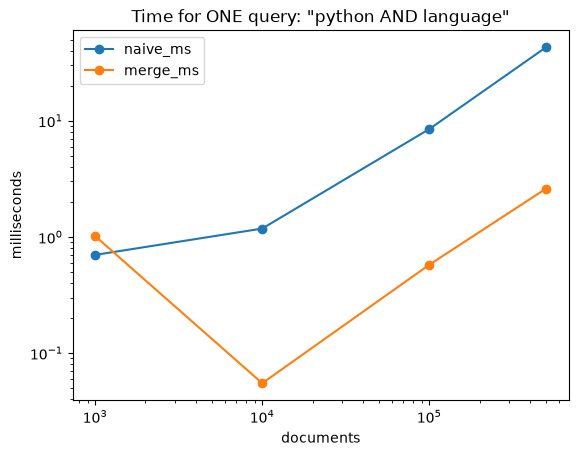

In [106]:
base_texts = list(docs.values())
random.seed(1)

def make_big_corpus(n):
    return [base_texts[i % len(base_texts)] + f" ref{random.randint(0, 10**6)}" for i in range(n)]

def naive_and_scan(corpus, w1, w2):
    return [i for i, t in enumerate(corpus) if w1 in t.lower() and w2 in t.lower()]

def build_index_list(corpus):
    idx = {}
    for i, t in enumerate(corpus):
        for term in set(preprocess(t)):
            idx.setdefault(term, []).append(i)
    return idx

sizes = [1_000, 10_000, 100_000, 500_000]
timings = []
for n in sizes:
    corpus = make_big_corpus(n)

    t0 = time.perf_counter()
    naive_hits = naive_and_scan(corpus, "python", "language")
    naive_ms = (time.perf_counter() - t0) * 1000

    t0 = time.perf_counter()
    idx = build_index_list(corpus)
    build_ms = (time.perf_counter() - t0) * 1000

    t0 = time.perf_counter()
    p1, p2 = idx.get(simple_stem("python"), []), idx.get(simple_stem("language"), [])
    merge_hits = intersect(p1, p2)
    merge_ms = (time.perf_counter() - t0) * 1000

    timings.append({"documents": n, "naive_ms": round(naive_ms, 2), "build_ms": round(build_ms, 1),
                     "merge_ms": round(merge_ms, 3), "naive_hits": len(naive_hits), "merge_hits": len(merge_hits)})
    print(timings[-1])

timing_df = pd.DataFrame(timings)
timing_df.plot(x="documents", y=["naive_ms", "merge_ms"], marker="o", logx=True, logy=True,
               title='Time for ONE query: "python AND language"')
plt.ylabel("milliseconds"); plt.show()

In [108]:
# TODO: using the LARGEST row of timing_df, compute the number of repeated queries
#       (break_even) at which building the index ONCE and then using `merge_ms` per
#       query becomes cheaper in TOTAL than repeating the naive scan every time.
#       Total naive cost for q queries:  q * naive_ms
#       Total indexed cost for q queries: build_ms + q * merge_ms
largest = timing_df.iloc[-1]

if largest["naive_ms"] <= largest["merge_ms"]:
    break_even = float("inf")
else:
    break_even = largest["build_ms"] / (largest["naive_ms"] - largest["merge_ms"])+ 1

print(f"Break-even after about {break_even:.0f} queries")

Break-even after about 54 queries


**Answer 7.1** In your own words, when does building an index pay off, and when might it not (think about a collection that is searched only once)?

*Your answer:*

It pays off when searching many documents many times. For only one search, building the index comsume much resources.

**Answer 7.2** `naive_hits` and `merge_hits` should be equal in every row. If they were not, what would that tell you about a bug in your preprocessing or your merge functions?

*Your answer:*
it euqal every row becusae it search for the same query.

## Part 8. Bonus: indexing Khmer text (optional, 15 min)
Khmer has no spaces between words, so `tokenize` (which splits on non-letters) does not work. A real system needs a **word segmenter** first.

In [112]:
khmer_docs = {
    "k1": 'ភ្នំពេញជារាជធានីនៃប្រទេសកម្ពុជា',
    "k2": 'អង្គរវត្តជាប្រាសាទដ៏ធំបំផុតក្នុងពិភពលោក',
    "k3": 'ខ្ញុំចូលចិត្តរៀនសរសេរកម្មវិធី',
}

# Without segmentation, tokenize() cannot split Khmer into separate words:
for doc_id, text in khmer_docs.items():
    print(doc_id, "->", tokenize(text) or "(no matches: our [a-z]+ pattern does not match Khmer script)")

# Try installing a Khmer segmenter and building a tiny index over the segmented tokens:
#   pip install khmer-nltk
from khmernltk import word_tokenize as khmer_word_tokenize
khmer_index = build_index({i: " ".join(khmer_word_tokenize(t)) for i, t in khmer_docs.items()})
print(khmer_index)

k1 -> (no matches: our [a-z]+ pattern does not match Khmer script)
k2 -> (no matches: our [a-z]+ pattern does not match Khmer script)
k3 -> (no matches: our [a-z]+ pattern does not match Khmer script)
{}


**Answer 8.1** After segmentation (if you installed a segmenter), does a Boolean AND query over the segmented tokens behave the way you would expect? What would you still need to check before trusting a Khmer segmenter for your project?

*Your answer:*

## Part 9. Team check-in and reflection (about 10 min in class; finish as homework)

**Team check-in:** If your team has already picked a project theme, discuss: which of today's steps (stop words, stemming) might need to be DIFFERENT for your corpus (for example, a Khmer corpus, or a corpus full of code or product names where stemming could hurt)?

**Reflection (4–6 sentences):** *What does an inverted index let you do that Lab 1's naive scan could not? Use at least one measurement from Part 7 as evidence. Then name one thing that is STILL broken after today's work, and which future session (see the course roadmap) will fix it.*

*Your reflection:*

An inverted index allows the system to search more relevant documents using keywords, and it is also faster because it finds the key terms first instead of scanning the whole document collection. Based on the lab results, scanning 500k documents in Lab 1 took 44 ms, while the merge_ms in Lab 2 took only 2.606 ms. It also eliminates the substring issue that returns unrelated documents, such as catalog when searching for cat. However, it is not perfect because it still has vocabulary mismatch problems. For example, car does not match related words, and stemming changes runners to runner, not run. One thing that could improve this is ranking.

---
### Submission checklist
- [ ] All `# TODO` cells completed and the notebook runs from top to bottom without errors
- [ ] All *Answer* cells written in your own words
- [ ] Part 6 comparison table produced and discussed
- [ ] Part 7 break-even calculation completed
- [ ] Notebook saved as `Lab2_<StudentID>.ipynb` and submitted as instructed